# Homework # 4 Naive BAYES Classifier

### Instructor - Dr. Uma Gajendragadkar

### Problem - Design and develop Machine learning model to predict Diabetes using Naive Bayes Algorithm. 

### Dataset - Diabetes dataset

This dataset consists of 768 observations & 8 numerical independent variables.
Dependent and target variable is OUTCOME. 1 means diabetes test result being positive, 0 means indicates negative.

Pregnancies: Number of Times Being Pregnant

Glucose: Plasma Glucose Concentration (a 2 hours in an oral glucose tolerance test)

BloodPressure: Diastolic Blood Pressure (mm Hg)

SkinThickness: Triceps Skin Fold Thickness (mm)

Insulin: 2-Hour Serum Insulin (mu U/ml)

BMI: Body Mass Index (weight in kg/(height in m)^2)

DiabetesPedigreeFunction: Diabetes Pedigree Function

Age: Age

Outcome: Class variable ( 0 - 1)



In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import MinMaxScaler, LabelEncoder, StandardScaler, RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, classification_report
from sklearn.model_selection import train_test_split, cross_validate
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.3f' % x)
pd.set_option('display.width', 500)
import warnings
warnings.filterwarnings('ignore')
import matplotlib.pyplot  as plt
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn import preprocessing
from sklearn.naive_bayes import GaussianNB

Step 1 - Write code to Read data from dataset into pandas dataframe

In [2]:
df = pd.read_csv("../data/diabetes.csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.600,0.627,50,1
1,1,85,66,29,0,26.600,0.351,31,0
2,8,183,64,0,0,23.300,0.672,32,1
3,1,89,66,23,94,28.100,0.167,21,0
4,0,137,40,35,168,43.100,2.288,33,1


Step 2 - a) Write code to display dataset info 
b) Print 10 rows from dataset.

In [3]:
# Step 2a - Display dataset info
df.info()

# Step 2b - Print the first 10 rows of the dataset
print(df.head(10))

# Summary statistics for every column
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin    BMI  DiabetesPedigreeFunction  Age  Outcome
0            6      148             72             35        0 33.600                     0.627   50        1
1            1       85        

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000,768.000,768.000,768.000,768.000,768.000,768.000,768.000,768.000
mean,3.845,120.895,69.105,20.536,79.799,31.993,0.472,33.241,0.349
std,3.370,31.973,19.356,15.952,115.244,7.884,0.331,11.760,0.477
min,0.000,0.000,0.000,0.000,0.000,0.000,0.078,21.000,0.000
25%,1.000,99.000,62.000,0.000,0.000,27.300,0.244,24.000,0.000
50%,3.000,117.000,72.000,23.000,30.500,32.000,0.372,29.000,0.000
75%,6.000,140.250,80.000,32.000,127.250,36.600,0.626,41.000,1.000
max,17.000,199.000,122.000,99.000,846.000,67.100,2.420,81.000,1.000


### Data Exploration Charts

Bar chart, histograms and a scatter plot to understand the dataset before modelling.

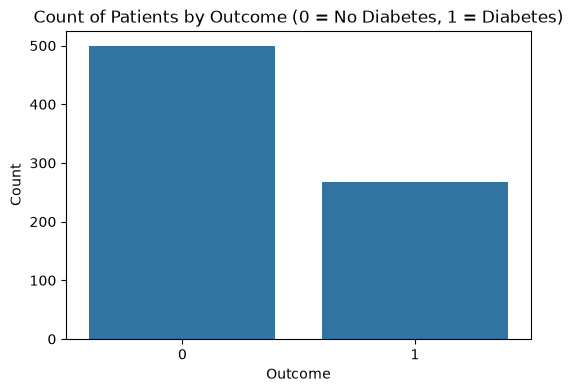

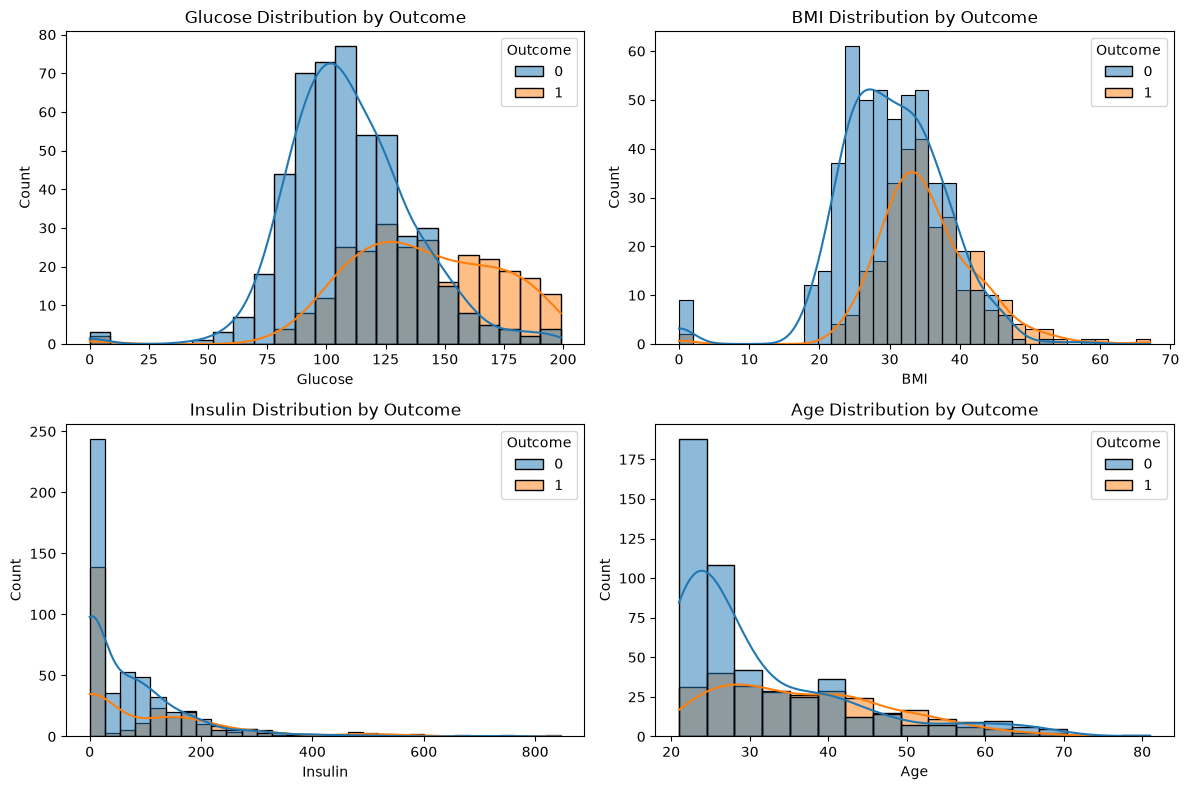

In [4]:
# Bar chart - number of patients in each Outcome class
plt.figure(figsize=(6, 4))
sns.countplot(x="Outcome", data=df)
plt.title("Count of Patients by Outcome (0 = No Diabetes, 1 = Diabetes)")
plt.xlabel("Outcome")
plt.ylabel("Count")
plt.show()

# Histograms - distribution of key features, split by Outcome
# (note the spike at 0 in Insulin and SkinThickness - impossible values,
#  they are treated as missing data in Step 5)
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
sns.histplot(data=df, x="Glucose", hue="Outcome", kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Glucose Distribution by Outcome")
sns.histplot(data=df, x="BMI", hue="Outcome", kde=True, ax=axes[0, 1])
axes[0, 1].set_title("BMI Distribution by Outcome")
sns.histplot(data=df, x="Insulin", hue="Outcome", kde=True, ax=axes[1, 0])
axes[1, 0].set_title("Insulin Distribution by Outcome")
sns.histplot(data=df, x="Age", hue="Outcome", kde=True, ax=axes[1, 1])
axes[1, 1].set_title("Age Distribution by Outcome")
plt.tight_layout()
plt.show()

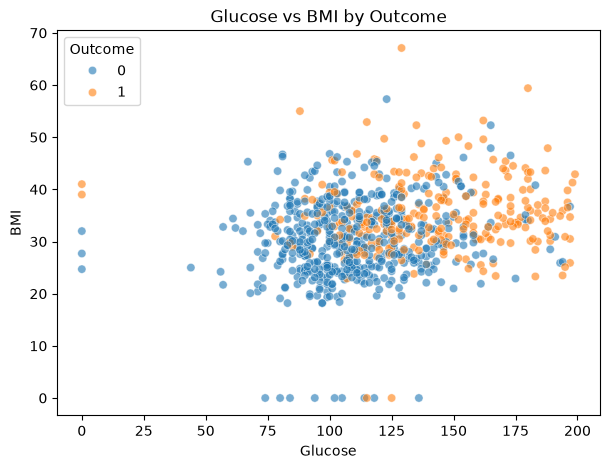

In [5]:
# Scatter plot - Glucose vs BMI, coloured by Outcome
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="Glucose", y="BMI", hue="Outcome", alpha=0.6)
plt.title("Glucose vs BMI by Outcome")
plt.xlabel("Glucose")
plt.ylabel("BMI")
plt.show()

Step 3 - Write code to remove Pregnancy column 

In [6]:
# Step 3 - Remove the Pregnancies column
df.drop("Pregnancies", axis=1, inplace=True)
df.head()

,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,148,72,35,0,33.600,0.627,50,1
1,85,66,29,0,26.600,0.351,31,0
2,183,64,0,0,23.300,0.672,32,1
3,89,66,23,94,28.100,0.167,21,0
4,137,40,35,168,43.100,2.288,33,1


Step 4 - Write code to display info of dataset and check shape of dataset.

In [7]:
# Step 4 - Display info of the dataset and check its shape
df.info()
print("Shape of the dataset:", df.shape)

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Glucose                   768 non-null    int64  
 1   BloodPressure             768 non-null    int64  
 2   SkinThickness             768 non-null    int64  
 3   Insulin                   768 non-null    int64  
 4   BMI                       768 non-null    float64
 5   DiabetesPedigreeFunction  768 non-null    float64
 6   Age                       768 non-null    int64  
 7   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(6)
memory usage: 48.1 KB
Shape of the dataset: (768, 8)


Step 5 - Write code to clean data

In [8]:
# In Glucose, BloodPressure, SkinThickness, Insulin and BMI, a value of 0 is not
# physically possible - those 0s are really missing values recorded as 0.
zero_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
df[zero_cols] = df[zero_cols].replace(0, np.nan)

print("Missing values after converting impossible 0s to NaN:")
print(df.isnull().sum())

# Fill the missing values with the mean of each column
df[zero_cols] = df[zero_cols].fillna(df[zero_cols].mean())

print("\nMissing values after filling with the column mean:")
print(df.isnull().sum())

Missing values after converting impossible 0s to NaN:
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

Missing values after filling with the column mean:
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


Step 6 - Split data into training and testing sets ( 80: 20 ratio)

In [9]:
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

Training set shape: (614, 7)
Testing set shape: (154, 7)


#### **Step #7: Initialize your model**




In [10]:
model = GaussianNB()
model

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09


#### **Step #8: Fit your model, test on the testing data, and create a visualization if applicable**

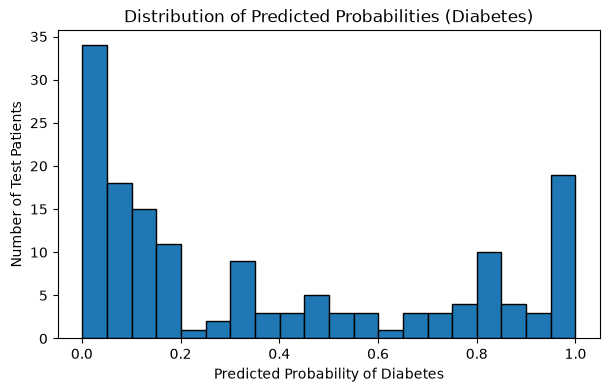

In [11]:
model.fit(X_train, y_train)

# Predicted probability of diabetes (class 1) for each test patient
y_prob = model.predict_proba(X_test)[:, 1]

# Visualization - distribution of the model's predicted probabilities
plt.figure(figsize=(7, 4))
plt.hist(y_prob, bins=20, edgecolor="black")
plt.title("Distribution of Predicted Probabilities (Diabetes)")
plt.xlabel("Predicted Probability of Diabetes")
plt.ylabel("Number of Test Patients")
plt.show()

Step 9 - Predict using model on test data

In [12]:
y_pred = model.predict(X_test)

print("First 10 predictions:      ", y_pred[:10])
print("First 10 actual values:    ", y_test.values[:10])
print("\nPredicted probabilities for the first 5 test patients:")
print(model.predict_proba(X_test)[:5])

First 10 predictions:       [0 0 0 0 1 0 0 0 1 1]
First 10 actual values:     [0 0 0 0 0 0 0 0 0 0]

Predicted probabilities for the first 5 test patients:
[[0.83076483 0.16923517]
 [0.88402042 0.11597958]
 [0.95949394 0.04050606]
 [0.87263172 0.12736828]
 [0.43975737 0.56024263]]


Step 10 -  Find accuracy of model

In [13]:
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy of the model:", accuracy)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy of the model: 0.7532467532467533

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.82      0.81        99
           1       0.66      0.64      0.65        55

    accuracy                           0.75       154
   macro avg       0.73      0.73      0.73       154
weighted avg       0.75      0.75      0.75       154



Step 11 - Confusion Matrix

In [14]:
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[81 18]
 [20 35]]


### Model Evaluation Charts

Confusion matrix plot and ROC curve for the trained model.

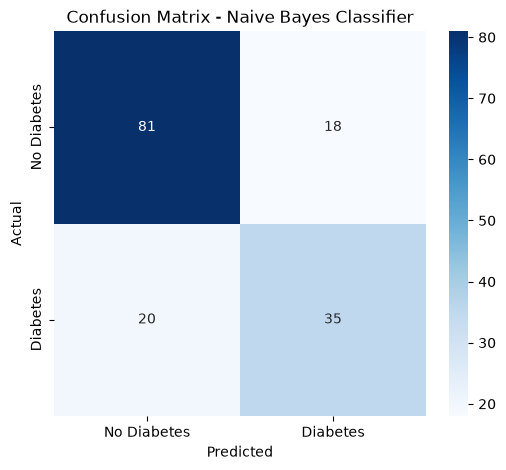

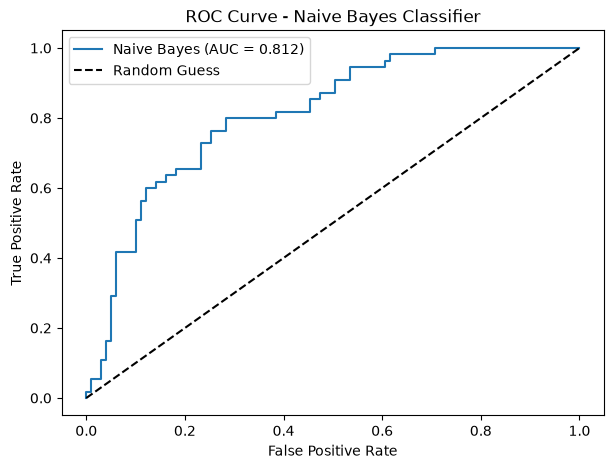

ROC AUC Score: 0.8117539026629935


In [15]:
from sklearn.metrics import roc_curve

# Plot of the Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No Diabetes", "Diabetes"],
            yticklabels=["No Diabetes", "Diabetes"])
plt.title("Confusion Matrix - Naive Bayes Classifier")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Naive Bayes (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random Guess")
plt.title("ROC Curve - Naive Bayes Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

print("ROC AUC Score:", auc)